In [1]:

# Phase 5 — NLP and Topic Modelling
# Step 5.1A — Environment setup and data loading

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate project root
project_folder = Path.cwd().resolve()

if not (project_folder / ".git").exists():
    project_folder = project_folder.parent

print("Python version:", sys.version.split()[0])
print("Project folder:", project_folder)
print("Project found:", (project_folder / ".git").exists())

# Load the saved 5,000-paper metadata
metadata_path = (
    project_folder / "results" / "arxiv_subset_metadata.csv"
)

assert metadata_path.exists(), (
    f"Metadata file not found: {metadata_path}"
)

papers_df = pd.read_csv(metadata_path)

print("\nDATASET LOADED")
print("Number of papers:", len(papers_df))
print("Columns:", papers_df.columns.tolist())

print("\nMISSING VALUES")
print(papers_df.isna().sum())

print("\nSAMPLE PAPER TITLES")
display(
    papers_df[["node idx", "title"]].head(10)
)

# Validate dataset
assert len(papers_df) == 5000
assert papers_df["node idx"].is_unique
assert papers_df["title"].notna().all()
assert papers_df["abstract"].notna().all()

print("\nPhase 5 dataset validation passed!")


Python version: 3.11.9
Project folder: C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis
Project found: True

DATASET LOADED
Number of papers: 5000
Columns: ['node idx', 'paper id', 'title', 'abstract']

MISSING VALUES
node idx    0
paper id    0
title       0
abstract    0
dtype: int64

SAMPLE PAPER TITLES


,node idx,title
0,0,evasion attacks against machine learning at te...
1,31,learning transformations for clustering and cl...
2,65,improved analysis for subspace pursuit algorit...
3,112,rappor randomized aggregatable privacy preserv...
4,148,efficient synthesis of network updates
5,156,the henchman problem measuring secrecy by the ...
6,218,diffusing private data over networks
7,226,adm cle approach for detecting slow variables ...
8,240,map support detection for greedy sparse signal...
9,244,supervised dimensionality reduction via distan...



Phase 5 dataset validation passed!


TEXT LENGTH STATISTICS


,title_word_count,abstract_word_count,full_text_word_count
count,5000.00,5000.00,5000.00
mean,8.56,172.55,181.11
std,2.90,57.18,57.60
min,2.00,11.00,21.00
25%,6.00,132.00,140.00
50%,8.00,169.00,177.00
75%,10.00,211.00,220.00
max,22.00,375.00,384.00


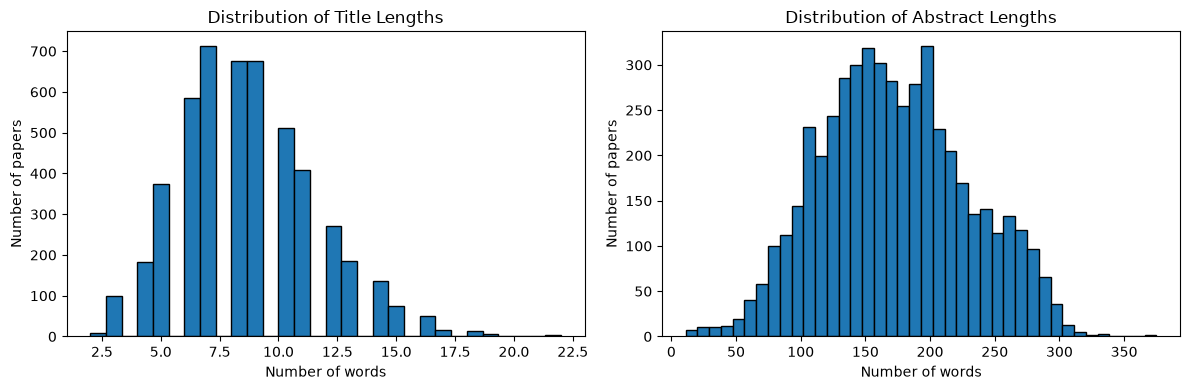


FIVE SHORTEST ABSTRACTS


,node idx,title,abstract_word_count
4943,167755,nearly linear time algorithms for graph partit...,11
1981,65762,adaptive gradient for adversarial perturbation...,16
4135,139087,grothendieck type inequalities in combinatoria...,16
4974,168525,oblivious stash shuffle,18
1485,49241,privacy compatibility for general utility metrics,19



FIVE LONGEST ABSTRACTS


,node idx,title,abstract_word_count
3535,117882,simple tabulation fast expanders double tabula...,375
2976,99295,topics in matrix sampling algorithms,369
2706,90201,a planetary nervous system for social mining a...,360
4619,156460,parameter free locality sensitive hashing for ...,354
1212,40389,poisoning attacks to graph based recommender s...,336


In [2]:

# Step 5.2A — Explore titles and abstracts

# Work with a copy to preserve the original data
nlp_df = papers_df.copy()

# Count words in titles and abstracts
nlp_df["title_word_count"] = (
    nlp_df["title"].str.split().str.len()
)

nlp_df["abstract_word_count"] = (
    nlp_df["abstract"].str.split().str.len()
)

# Combine titles and abstracts
nlp_df["full_text"] = (
    nlp_df["title"].str.strip()
    + " "
    + nlp_df["abstract"].str.strip()
)

nlp_df["full_text_word_count"] = (
    nlp_df["full_text"].str.split().str.len()
)

# Descriptive statistics
print("TEXT LENGTH STATISTICS")

display(
    nlp_df[
        [
            "title_word_count",
            "abstract_word_count",
            "full_text_word_count"
        ]
    ].describe().round(2)
)

# Visualise word counts
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    nlp_df["title_word_count"],
    bins=30,
    edgecolor="black"
)
axes[0].set_title("Distribution of Title Lengths")
axes[0].set_xlabel("Number of words")
axes[0].set_ylabel("Number of papers")

axes[1].hist(
    nlp_df["abstract_word_count"],
    bins=40,
    edgecolor="black"
)
axes[1].set_title("Distribution of Abstract Lengths")
axes[1].set_xlabel("Number of words")
axes[1].set_ylabel("Number of papers")

plt.tight_layout()
plt.show()

# Inspect the longest and shortest abstracts
print("\nFIVE SHORTEST ABSTRACTS")
display(
    nlp_df.nsmallest(5, "abstract_word_count")[
        ["node idx", "title", "abstract_word_count"]
    ]
)

print("\nFIVE LONGEST ABSTRACTS")
display(
    nlp_df.nlargest(5, "abstract_word_count")[
        ["node idx", "title", "abstract_word_count"]
    ]
)


In [3]:

# Step 5.2B — Text preprocessing

import re
import pandas as pd

def preprocess_text(text):
    """
    Apply light preprocessing while preserving
    useful technical terminology.
    """
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Replace punctuation and special characters with spaces
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Normalize repeated whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply preprocessing
nlp_df["clean_text"] = nlp_df["full_text"].apply(
    preprocess_text
)

# Calculate cleaned text lengths
nlp_df["clean_word_count"] = (
    nlp_df["clean_text"].str.split().str.len()
)

# Check for empty documents
empty_documents = (
    nlp_df["clean_text"].str.len() == 0
).sum()

print("PREPROCESSING RESULTS")
print("Total documents:", len(nlp_df))
print("Empty documents:", empty_documents)
print(
    "Average cleaned word count:",
    round(nlp_df["clean_word_count"].mean(), 2)
)

# Compare original and cleaned text
sample = nlp_df.iloc[0]

print("\nORIGINAL TEXT:")
print(sample["full_text"][:500])

print("\nCLEANED TEXT:")
print(sample["clean_text"][:500])

# Validate
assert empty_documents == 0
assert len(nlp_df) == 5000

print("\nText preprocessing completed successfully!")


PREPROCESSING RESULTS
Total documents: 5000
Empty documents: 0
Average cleaned word count: 189.62

ORIGINAL TEXT:
evasion attacks against machine learning at test time In security-sensitive applications, the success of machine learning depends on a thorough vetting of their resistance to adversarial data. In one pertinent, well-motivated attack scenario, an adversary may attempt to evade a deployed system at test time by carefully manipulating attack samples. In this work, we present a simple but effective gradient-based approach that can be exploited to systematically assess the security of several, widely

CLEANED TEXT:
evasion attacks against machine learning at test time in security sensitive applications the success of machine learning depends on a thorough vetting of their resistance to adversarial data in one pertinent well motivated attack scenario an adversary may attempt to evade a deployed system at test time by carefully manipulating attack samples in this work we present a

In [4]:

# Step 5.3A — TF-IDF vectorization

from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
import pandas as pd
import time

start = time.perf_counter()

tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.90,
    max_features=10000,
    sublinear_tf=True,
    dtype=np.float64
)

tfidf_matrix = tfidf_vectorizer.fit_transform(
    nlp_df["clean_text"]
)

tfidf_runtime = time.perf_counter() - start

feature_names = tfidf_vectorizer.get_feature_names_out()

print("TF-IDF RESULTS")
print("Matrix shape:", tfidf_matrix.shape)
print("Number of documents:", tfidf_matrix.shape[0])
print("Number of features:", tfidf_matrix.shape[1])
print("Non-zero entries:", tfidf_matrix.nnz)
print("Runtime (seconds):", round(tfidf_runtime, 3))

# Percentage of zero values
total_entries = (
    tfidf_matrix.shape[0] * tfidf_matrix.shape[1]
)

sparsity = 100 * (
    1 - tfidf_matrix.nnz / total_entries
)

print("Sparsity (%):", round(sparsity, 2))

# Highest mean TF-IDF scores across the collection
mean_scores = np.asarray(
    tfidf_matrix.mean(axis=0)
).ravel()

top_indices = np.argsort(mean_scores)[-20:][::-1]

top_terms_df = pd.DataFrame({
    "term": feature_names[top_indices],
    "mean_tfidf": mean_scores[top_indices]
})

print("\nTOP 20 TERMS BY MEAN TF-IDF")
display(top_terms_df.round(5))

# Validate
assert tfidf_matrix.shape[0] == 5000
assert tfidf_matrix.nnz > 0

print("\nTF-IDF vectorization completed successfully!")


TF-IDF RESULTS
Matrix shape: (5000, 10000)
Number of documents: 5000
Number of features: 10000
Non-zero entries: 440150
Runtime (seconds): 3.279
Sparsity (%): 99.12

TOP 20 TERMS BY MEAN TF-IDF


,term,mean_tfidf
0,data,0.02531
1,learning,0.02268
2,privacy,0.02192
3,algorithm,0.02086
4,algorithms,0.01825
5,problem,0.01791
6,model,0.01692
7,based,0.01691
8,paper,0.01440
9,time,0.01431



TF-IDF vectorization completed successfully!


In [5]:

# Step 5.3B — Refine TF-IDF vocabulary

from sklearn.feature_extraction.text import (
    TfidfVectorizer,
    ENGLISH_STOP_WORDS
)

# Generic academic words that provide limited topic information
academic_stopwords = {
    "paper",
    "papers",
    "result",
    "results",
    "using",
    "used",
    "use",
    "based",
    "approach",
    "approaches",
    "method",
    "methods",
    "new",
    "propose",
    "proposed",
    "present",
    "show",
    "shows",
    "study",
    "studies",
    "work",
    "demonstrate",
    "demonstrates"
}

custom_stopwords = (
    set(ENGLISH_STOP_WORDS) | academic_stopwords
)

# Rebuild TF-IDF using refined stopwords
tfidf_vectorizer = TfidfVectorizer(
    stop_words=list(custom_stopwords),
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.90,
    max_features=10000,
    sublinear_tf=True,
    dtype=np.float64
)

tfidf_matrix = tfidf_vectorizer.fit_transform(
    nlp_df["clean_text"]
)

feature_names = tfidf_vectorizer.get_feature_names_out()

# Recalculate highest mean TF-IDF terms
mean_scores = np.asarray(
    tfidf_matrix.mean(axis=0)
).ravel()

top_indices = np.argsort(mean_scores)[-20:][::-1]

top_terms_df = pd.DataFrame({
    "term": feature_names[top_indices],
    "mean_tfidf": mean_scores[top_indices]
})

print("REFINED TF-IDF RESULTS")
print("Matrix shape:", tfidf_matrix.shape)
print("Non-zero entries:", tfidf_matrix.nnz)

print("\nTOP 20 TERMS AFTER REFINEMENT")
display(top_terms_df.round(5))

print("\nRefined TF-IDF matrix ready for topic modelling!")


REFINED TF-IDF RESULTS
Matrix shape: (5000, 10000)
Non-zero entries: 410152

TOP 20 TERMS AFTER REFINEMENT


,term,mean_tfidf
0,data,0.02572
1,learning,0.02303
2,privacy,0.02217
3,algorithm,0.02113
4,algorithms,0.01849
5,problem,0.01815
6,model,0.01717
7,time,0.01447
8,information,0.01415
9,networks,0.01288



Refined TF-IDF matrix ready for topic modelling!


In [6]:

# Step 5.4A — Initial NMF topic model

from sklearn.decomposition import NMF
import numpy as np
import pandas as pd
import time

N_TOPICS = 10
RANDOM_SEED = 42

start = time.perf_counter()

nmf_model = NMF(
    n_components=N_TOPICS,
    init="nndsvda",
    random_state=RANDOM_SEED,
    max_iter=400
)

# Document-topic matrix
document_topics = nmf_model.fit_transform(
    tfidf_matrix
)

# Topic-word matrix
topic_words = nmf_model.components_

nmf_runtime = time.perf_counter() - start

print("NMF MODEL RESULTS")
print("Number of topics:", N_TOPICS)
print("Document-topic matrix:", document_topics.shape)
print("Topic-word matrix:", topic_words.shape)
print("Reconstruction error:", round(nmf_model.reconstruction_err_, 4))
print("Runtime (seconds):", round(nmf_runtime, 2))
print("Iterations:", nmf_model.n_iter_)

# Extract top 12 terms per topic
top_n_words = 12

topic_results = []

for topic_id, weights in enumerate(topic_words):

    top_indices = np.argsort(weights)[::-1][:top_n_words]

    top_terms = feature_names[top_indices]

    topic_results.append({
        "topic": topic_id,
        "top_terms": ", ".join(top_terms)
    })

topics_df = pd.DataFrame(topic_results)

print("\nDISCOVERED TOPICS")
display(topics_df)

# Assign each paper its highest-scoring topic
nlp_df["dominant_topic"] = document_topics.argmax(axis=1)

# Check how many papers are assigned to each topic
topic_counts = (
    nlp_df["dominant_topic"]
    .value_counts()
    .sort_index()
)

print("\nPAPERS PER TOPIC")
display(topic_counts.to_frame("paper_count"))

# Validation
assert document_topics.shape == (5000, N_TOPICS)
assert topic_words.shape == (N_TOPICS, tfidf_matrix.shape[1])

print("\nInitial NMF topic modelling completed successfully!")


NMF MODEL RESULTS
Number of topics: 10
Document-topic matrix: (5000, 10)
Topic-word matrix: (10, 10000)
Reconstruction error: 68.3077
Runtime (seconds): 1.7
Iterations: 166

DISCOVERED TOPICS


,topic,top_terms
0,0,"matrix, rank, low rank, low, subspace, approxi..."
1,1,"learning, data, federated, machine, machine le..."
2,2,"privacy, differential privacy, differential, p..."
3,3,"regret, bandit, armed, bandits, multi armed, m..."
4,4,"sensing, sparse, recovery, signal, measurement..."
5,5,"graph, community, clustering, graphs, network,..."
6,6,"neural, adversarial, deep, neural networks, ne..."
7,7,"convex, optimization, gradient, online, stocha..."
8,8,"log, epsilon, lower, time, complexity, bounds,..."
9,9,"channel, capacity, gaussian, region, interfere..."



PAPERS PER TOPIC


,paper_count
dominant_topic,
0,317
1,759
2,678
3,477
4,383
5,616
6,500
7,475
8,612



Initial NMF topic modelling completed successfully!


In [7]:

# Step 5.5A — Evaluate different numbers of NMF topics

from sklearn.decomposition import NMF
import numpy as np
import pandas as pd
import time

topic_counts_to_test = [5, 8, 10, 12, 15, 20]
evaluation_results = []

for k in topic_counts_to_test:

    start = time.perf_counter()

    model = NMF(
        n_components=k,
        init="nndsvda",
        random_state=42,
        max_iter=400
    )

    W = model.fit_transform(tfidf_matrix)
    H = model.components_

    runtime = time.perf_counter() - start

    # Top 10 terms for each topic
    top_word_indices = np.argsort(H, axis=1)[:, -10:]

    # Topic diversity: proportion of unique top terms
    all_top_terms = top_word_indices.flatten()

    topic_diversity = (
        len(np.unique(all_top_terms)) / len(all_top_terms)
    )

    evaluation_results.append({
        "n_topics": k,
        "reconstruction_error": model.reconstruction_err_,
        "topic_diversity": topic_diversity,
        "runtime_seconds": runtime,
        "iterations": model.n_iter_
    })

evaluation_df = pd.DataFrame(evaluation_results)

print("NMF TOPIC COUNT EVALUATION")
display(evaluation_df.round(4))


NMF TOPIC COUNT EVALUATION


,n_topics,reconstruction_error,topic_diversity,runtime_seconds,iterations
0,5,68.8966,0.9600,0.7127,129
1,8,68.5254,0.9250,0.8640,103
2,10,68.3077,0.9200,1.6050,166
3,12,68.1264,0.9333,0.9354,64
4,15,67.8775,0.9200,1.6354,87
5,20,67.5674,0.8850,2.5716,117


In [8]:

# Step 5.5B — Inspect topic interpretability

from sklearn.decomposition import NMF
import numpy as np
import pandas as pd

candidate_topic_counts = [10, 12, 15]
candidate_models = {}

for k in candidate_topic_counts:

    model = NMF(
        n_components=k,
        init="nndsvda",
        random_state=42,
        max_iter=400
    )

    model.fit(tfidf_matrix)
    candidate_models[k] = model

    topic_rows = []

    for topic_id, weights in enumerate(model.components_):
        top_indices = np.argsort(weights)[::-1][:10]

        topic_rows.append({
            "topic": topic_id,
            "top_terms": ", ".join(feature_names[top_indices])
        })

    print(f"\n{'=' * 20}")
    print(f"NMF MODEL: {k} TOPICS")
    print(f"{'=' * 20}")

    display(pd.DataFrame(topic_rows))



NMF MODEL: 10 TOPICS


,topic,top_terms
0,0,"matrix, rank, low rank, low, subspace, approxi..."
1,1,"learning, data, federated, machine, machine le..."
2,2,"privacy, differential privacy, differential, p..."
3,3,"regret, bandit, armed, bandits, multi armed, m..."
4,4,"sensing, sparse, recovery, signal, measurement..."
5,5,"graph, community, clustering, graphs, network,..."
6,6,"neural, adversarial, deep, neural networks, ne..."
7,7,"convex, optimization, gradient, online, stocha..."
8,8,"log, epsilon, lower, time, complexity, bounds,..."
9,9,"channel, capacity, gaussian, region, interfere..."



NMF MODEL: 12 TOPICS


,topic,top_terms
0,0,"graph, graphs, spectral, laplacian, edges, ver..."
1,1,"privacy, differential privacy, differential, p..."
2,2,"log, lower, bounds, bound, epsilon, complexity..."
3,3,"regret, bandit, armed, bandits, multi armed, m..."
4,4,"sensing, sparse, recovery, signal, measurement..."
5,5,"community, detection, communities, community d..."
6,6,"neural, deep, networks, neural networks, netwo..."
7,7,"convex, optimization, gradient, online, stocha..."
8,8,"learning, data, federated, federated learning,..."
9,9,"clustering, data, subspace, subspace clusterin..."



NMF MODEL: 15 TOPICS


,topic,top_terms
0,0,"log, epsilon, lower, complexity, bounds, bound..."
1,1,"privacy, users, data, user, preserving, privac..."
2,2,"privacy, differential privacy, differential, p..."
3,3,"regret, bandit, armed, bandits, multi armed, m..."
4,4,"sensing, sparse, recovery, signal, measurement..."
5,5,"community, detection, community detection, com..."
6,6,"neural, deep, networks, neural networks, netwo..."
7,7,"convex, optimization, gradient, online, stocha..."
8,8,"clustering, subspace, data, subspace clusterin..."
9,9,"channel, gaussian, capacity, region, interfere..."


In [9]:

# Step 5.5C — Inspect representative papers for 12 topics

import numpy as np
import pandas as pd

selected_k = 12

selected_model = candidate_models[selected_k]

# Get document-topic weights
selected_document_topics = selected_model.transform(
    tfidf_matrix
)

# Highest-scoring topic for each paper
nlp_df["dominant_topic"] = selected_document_topics.argmax(axis=1)

# Strength of the dominant topic
nlp_df["topic_strength"] = selected_document_topics.max(axis=1)

representative_rows = []

for topic_id in range(selected_k):

    # Rank all papers by their weight for this topic
    top_indices = np.argsort(
        selected_document_topics[:, topic_id]
    )[::-1][:3]

    for rank, idx in enumerate(top_indices, start=1):

        representative_rows.append({
            "topic": topic_id,
            "rank": rank,
            "title": nlp_df.iloc[idx]["title"],
            "topic_weight": selected_document_topics[idx, topic_id]
        })

representative_df = pd.DataFrame(representative_rows)

print("TOP 3 REPRESENTATIVE PAPERS PER TOPIC")
display(representative_df.round(4))

print("\nDOMINANT TOPIC DISTRIBUTION")
display(
    nlp_df["dominant_topic"]
    .value_counts()
    .sort_index()
    .rename_axis("topic")
    .to_frame("paper_count")
)


TOP 3 REPRESENTATIVE PAPERS PER TOPIC


,topic,rank,title,topic_weight
0,0,1,spectral sparsification of graphs,0.1288
1,0,2,towards scalable spectral sparsification of di...,0.1177
2,0,3,grass spectral sparsification leveraging scala...,0.1153
3,1,1,universally utility maximizing privacy mechanisms,0.1694
4,1,2,differential privacy by sampling,0.1616
5,1,3,optimizing batch linear queries under exact an...,0.1562
6,2,1,efficient algorithms and lower bounds for robu...,0.1784
7,2,2,optimal identity testing with high probability,0.1673
8,2,3,statistical query lower bounds for robust esti...,0.1651
9,3,1,modeling human decision making in generalized ...,0.2158



DOMINANT TOPIC DISTRIBUTION


,paper_count
topic,
0,207
1,704
2,607
3,490
4,359
5,284
6,337
7,408
8,588


In [10]:

# Step 5.6A — Save final NMF topic results

from pathlib import Path
import numpy as np
import pandas as pd

topic_labels = {
    0: "Graph Theory and Spectral Methods",
    1: "Differential Privacy",
    2: "Theoretical Bounds and Complexity",
    3: "Multi-Armed Bandits and Regret",
    4: "Compressed Sensing and Sparse Recovery",
    5: "Community Detection",
    6: "Deep Learning and Neural Networks",
    7: "Convex and Stochastic Optimization",
    8: "Federated Learning",
    9: "Subspace Clustering",
    10: "Matrix Decomposition and Low-Rank Methods",
    11: "Adversarial Machine Learning"
}

results_folder = project_folder / "results"
results_folder.mkdir(parents=True, exist_ok=True)

# Save paper-level topic assignments
paper_topics_df = nlp_df[
    ["node idx", "paper id", "title", "dominant_topic", "topic_strength"]
].copy()

paper_topics_df["topic_label"] = (
    paper_topics_df["dominant_topic"].map(topic_labels)
)

# Save all 12 topic weights for each paper
for topic_id in range(12):
    paper_topics_df[f"topic_{topic_id}_weight"] = (
        selected_document_topics[:, topic_id]
    )

paper_topics_df.to_csv(
    results_folder / "arxiv_paper_topics.csv",
    index=False
)

# Save topic descriptions and keywords
topic_summary_rows = []

for topic_id, weights in enumerate(selected_model.components_):

    top_indices = np.argsort(weights)[::-1][:12]

    topic_summary_rows.append({
        "topic": topic_id,
        "topic_label": topic_labels[topic_id],
        "top_terms": ", ".join(feature_names[top_indices]),
        "paper_count": int(
            (nlp_df["dominant_topic"] == topic_id).sum()
        )
    })

topic_summary_df = pd.DataFrame(topic_summary_rows)

topic_summary_df.to_csv(
    results_folder / "arxiv_topic_summary.csv",
    index=False
)

# Validate that the saved assignments match the original metadata
assert len(paper_topics_df) == 5000
assert paper_topics_df["node idx"].is_unique
assert paper_topics_df["topic_label"].notna().all()
assert paper_topics_df["dominant_topic"].nunique() == 12
assert topic_summary_df["paper_count"].sum() == 5000

print("FINAL NMF RESULTS SAVED")
print("Paper assignments:", results_folder / "arxiv_paper_topics.csv")
print("Topic summary:", results_folder / "arxiv_topic_summary.csv")

print("\nTOPIC SUMMARY")
display(
    topic_summary_df[
        ["topic", "topic_label", "paper_count"]
    ]
)

print("\nAll validation checks passed!")


FINAL NMF RESULTS SAVED
Paper assignments: C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\results\arxiv_paper_topics.csv
Topic summary: C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\results\arxiv_topic_summary.csv

TOPIC SUMMARY


,topic,topic_label,paper_count
0,0,Graph Theory and Spectral Methods,207
1,1,Differential Privacy,704
2,2,Theoretical Bounds and Complexity,607
3,3,Multi-Armed Bandits and Regret,490
4,4,Compressed Sensing and Sparse Recovery,359
5,5,Community Detection,284
6,6,Deep Learning and Neural Networks,337
7,7,Convex and Stochastic Optimization,408
8,8,Federated Learning,588
9,9,Subspace Clustering,457



All validation checks passed!


In [ ]:

# Step 5.6B — Commit NLP topic modelling milestone

import subprocess

def run_git(args):
    result = subprocess.run(
        ["git"] + args,
        cwd=project_folder,
        capture_output=True,
        text=True,
        check=True
    )
    if result.stdout.strip():
        print(result.stdout)
    if result.stderr.strip():
        print(result.stderr)

# Check repository status
run_git(["status", "--short"])

# Stage only the completed NLP files
run_git([
    "add",
    "notebooks/06_nlp_topic_modeling.ipynb",
    "results/arxiv_paper_topics.csv",
    "results/arxiv_topic_summary.csv"
])

# Review staged changes
run_git(["diff", "--cached", "--stat"])

# Commit the milestone
run_git([
    "commit",
    "-m",
    "Complete TF-IDF and NMF topic modelling on arXiv subset"
])

# Push to GitHub
run_git(["push", "origin", "HEAD"])

print("\nNLP topic modelling milestone committed and pushed!")
